# DS201 - LAB 4 - ENCODER-DECODER VÀ ATTENTION CHO DỊCH MÁY ANH - VIỆT

- **MSSV:** 23521117
- **Dữ liệu:** small-PhoMT (train 20.000 / dev 2.000 / test 2.000 cặp câu; sau khi lọc câu <= 50 từ còn 18607 / 1901 / 1786)
- **Nội dung:** 3 bài tập Phần C - Seq2Seq LSTM không attention (Bài 1), có Bahdanau attention (Bài 2), có Luong attention (Bài 3).

## 0. Chuẩn bị môi trường

In [1]:
# Cài 2 thư viện chấm điểm (Colab đã có sẵn torch, numpy, pandas, matplotlib)
%pip install -q rouge-score sacrebleu

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# Import thư viện
import hashlib, json, random, sys, time, unicodedata, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

In [3]:
# Cấu hình chung theo Phần C (giữ nguyên cho cả 3 mô hình để so sánh công bằng)
cfg = dict(
    emb=256, hidden=256, layers=3,      # 3 lớp LSTM mỗi bên, hidden 256
    dropout=0.3, batch=32, lr=1e-3,     # Adam
    teacher_ratio=0.5,                  # xác suất dùng token đúng khi huấn luyện
    epochs=10,                          # tối đa 10 epoch, giữ checkpoint ROUGE-L dev tốt nhất
    max_words=50,                       # giữ câu <= 50 từ
    vocab_limit=10000, min_freq=2,
    train_limit=None, dev_limit=None,   # None = dùng toàn bộ train/dev
    seed=42,
)

# QUICK_RUN=True: chạy thử nhanh cấu hình nhỏ để kiểm tra code (KHÔNG dùng cho kết quả nộp)
QUICK_RUN = False
if QUICK_RUN:
    cfg.update(emb=64, hidden=64, layers=1, epochs=2, max_words=25,
               vocab_limit=3000, train_limit=512, dev_limit=64)

for k, v in cfg.items():
    print(f'{k:14}= {v}')

emb           = 256
hidden        = 256
layers        = 3
dropout       = 0.3
batch         = 32
lr            = 0.001
teacher_ratio = 0.5
epochs        = 10
max_words     = 50
vocab_limit   = 10000
min_freq      = 2
train_limit   = None
dev_limit     = None
seed          = 42


In [4]:
# Seed và thiết bị
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(cfg['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')
if device.type == 'cpu':
    print('CẢNH BÁO: đang chạy CPU, cấu hình Phần C sẽ rất chậm. Hãy bật GPU trong Colab.')

PyTorch: 2.14.1+cu130 | device: cuda | Tesla T4


In [5]:
# Thư mục làm việc: trên Colab lưu vào Google Drive để không mất kết quả khi bị ngắt
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    LAB = Path('/content/drive/MyDrive/DS201_Lab4')
else:
    LAB = Path.cwd()
DATA = LAB/'data'
ART = LAB/('artifacts_quick' if QUICK_RUN else 'artifacts')
DATA.mkdir(parents=True, exist_ok=True)
ART.mkdir(parents=True, exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']
print('Dữ liệu  :', DATA)
print('Kết quả  :', ART)

Mounted at /content/drive
Dữ liệu  : /content/drive/MyDrive/DS201_Lab4/data
Kết quả  : /content/drive/MyDrive/DS201_Lab4/artifacts


## 1. Dữ liệu small-PhoMT

Tải 3 tệp JSON từ thư mục Google Drive của đề, kiểm tra SHA-256 để chắc chắn đúng dữ liệu gốc. Tiền xử lý: bỏ BOM, chuẩn hóa Unicode NFC, chữ thường, tách theo khoảng trắng. Chỉ giữ cặp câu có cả hai phía dài 1-50 từ.

In [6]:
# Danh sách tệp, link tải và SHA-256 (lấy từ notebook mẫu của môn)
DATA_FILES = [
    {'file': 'small-train.json',
     'url': 'https://drive.google.com/uc?export=download&id=1-eG6FeF-v__rsf77iWurddahXbyjTYh5',
     'sha256': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba'},
    {'file': 'small-dev.json',
     'url': 'https://drive.google.com/uc?export=download&id=1hoTd2hFwjSeFThlPm6YpN0NW5ePXS3Jc',
     'sha256': 'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9'},
    {'file': 'small-test.json',
     'url': 'https://drive.google.com/uc?export=download&id=1_3L25SH1_jaEfOjpmpgnfMik4N3MxSyn',
     'sha256': '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'},
]

def sha256(data):
    return hashlib.sha256(data).hexdigest()

def download(item, path):
    # Thử urllib trước, nếu không được thì dùng gdown (có sẵn trên Colab)
    try:
        with urllib.request.urlopen(item['url'], timeout=90) as r:
            content = r.read()
        if sha256(content) == item['sha256']:
            path.write_bytes(content)
            return
    except Exception as e:
        print('urllib lỗi:', e)
    import gdown
    gdown.download(item['url'], str(path), quiet=True)

for item in DATA_FILES:
    path = DATA/item['file']
    if not path.exists():
        download(item, path)
    if not path.exists() or sha256(path.read_bytes()) != item['sha256']:
        raise ValueError('Không tải được hoặc sai checksum: ' + item['file'])
print('3/3 tệp dữ liệu khớp SHA-256.')

3/3 tệp dữ liệu khớp SHA-256.


In [7]:
# Chuẩn hóa: bỏ BOM, NFC, chữ thường, tách theo khoảng trắng
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()

# Đọc 3 tệp và lọc theo độ dài
raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    raw[split] = json.loads((DATA/f'small-{split}.json').read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        src, tgt = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(src) <= cfg['max_words'] and 1 <= len(tgt) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=src, tgt=tgt))

assert [len(raw[s]) for s in raw] == [20000, 2000, 2000]
stats = pd.DataFrame([
    dict(split=s, goc=len(raw[s]), sau_loc=len(filtered[s]),
         ti_le=len(filtered[s])/len(raw[s]),
         tb_tu_EN=np.mean([len(r['src']) for r in filtered[s]]),
         tb_tu_VI=np.mean([len(r['tgt']) for r in filtered[s]]))
    for s in filtered])
print(stats.round(3).to_string(index=False))
print('\nVí dụ:', ' '.join(filtered['train'][0]['src']), '→', ' '.join(filtered['train'][0]['tgt']))

split   goc  sau_loc  ti_le  tb_tu_EN  tb_tu_VI
train 20000    18607  0.930    17.283    20.581
  dev  2000     1901  0.950    18.613    23.169
 test  2000     1786  0.893    19.659    24.654

Ví dụ: it begins with a countdown . → câu chuyện bắt đầu với buổi lễ đếm ngược .


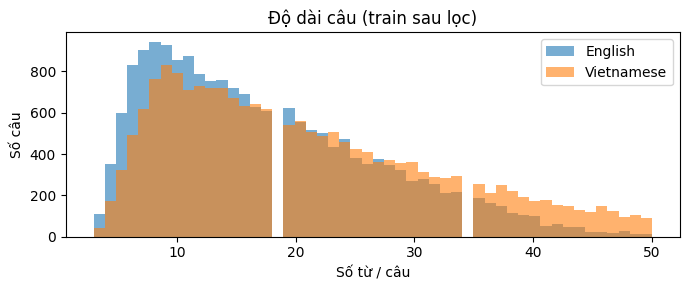

In [8]:
# Phân bố độ dài câu trong train sau lọc
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist([len(r['src']) for r in filtered['train']], bins=50, alpha=0.6, label='English')
ax.hist([len(r['tgt']) for r in filtered['train']], bins=50, alpha=0.6, label='Vietnamese')
ax.set_xlabel('Số từ / câu'); ax.set_ylabel('Số câu'); ax.set_title('Độ dài câu (train sau lọc)')
ax.legend(); fig.tight_layout(); fig.savefig(ART/'length_hist.png', dpi=150); plt.show()

### Từ điển, batch và DataLoader

Mỗi ngôn ngữ một từ điển, chỉ xây từ train (không nhìn dev/test), giữ tối đa 10.000 token có tần suất >= 2, cùng 4 token đặc biệt PAD/UNK/BOS/EOS. Câu nguồn thêm EOS; câu đích có BOS...EOS, decoder đọc `tgt[:, :-1]` để dự đoán `tgt[:, 1:]`. Câu tham chiếu dùng để chấm điểm giữ nguyên chữ gốc (không đổi thành UNK).

In [9]:
def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq'] and t not in SPECIAL]
    return {tok: i for i, tok in enumerate(SPECIAL + keep[:cfg['vocab_limit'] - 4])}

src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}

def encode(seq, vocab):
    return [vocab.get(t, UNK) for t in seq]

def unk_rate(rows, key, vocab):
    toks = [t for r in rows for t in r[key]]
    return sum(t not in vocab for t in toks) / len(toks)

print('Từ điển Anh / Việt:', len(src_vocab), '/', len(tgt_vocab))
print(f"Tỉ lệ UNK trên test — EN: {unk_rate(filtered['test'], 'src', src_vocab):.2%}"
      f" | VI: {unk_rate(filtered['test'], 'tgt', tgt_vocab):.2%}")

Từ điển Anh / Việt: 8943 / 4003
Tỉ lệ UNK trên test — EN: 7.31% | VI: 1.87%


In [10]:
def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab) + [EOS]) for r in rows]
    tgt = [torch.tensor([BOS] + encode(r['tgt'], tgt_vocab) + [EOS]) for r in rows]
    return dict(src=pad_sequence(src, batch_first=True, padding_value=PAD),
                lengths=torch.tensor([len(x) for x in src]),
                tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
                refs=[' '.join(r['tgt']) for r in rows],
                ids=[r['id'] for r in rows])

def choose(rows, limit):
    if limit is None or len(rows) <= limit:
        return rows
    idx = np.random.default_rng(cfg['seed']).permutation(len(rows))[:limit]
    return [rows[int(i)] for i in idx]

def loader(rows, shuffle=False, seed=None):
    # Generator cố định theo epoch: 3 mô hình thấy cùng thứ tự batch,
    # và khi huấn luyện tiếp sau khi Colab ngắt thứ tự vẫn giống chạy liền
    g = torch.Generator().manual_seed(cfg['seed'] if seed is None else seed)
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle,
                      collate_fn=collate, generator=g)

train_rows = choose(filtered['train'], cfg['train_limit'])
dev_rows = choose(filtered['dev'], cfg['dev_limit'])
test_rows = filtered['test']
print('Train / dev / test:', len(train_rows), len(dev_rows), len(test_rows))
print('Số batch train mỗi epoch:', len(loader(train_rows)))

Train / dev / test: 18607 1901 1786
Số batch train mỗi epoch: 582


## 2. Mô hình Seq2Seq

**Encoder** - Embedding -> LSTM 3 lớp (có packing để bỏ qua PAD). Trả về `memory` [B, S, H] (toàn bộ trạng thái ẩn, dùng cho attention) và `(h, c)` [3, B, H] để khởi tạo decoder.

**Decoder** có 3 chế độ:

| Chế độ | Query của attention | Hàm điểm | Context dùng ở đâu |
|---|---|---|---|
| `none` (Bài 1) | - | - | Decoder chỉ nhận embedding, toàn bộ thông tin câu nguồn nằm trong `(h, c)` |
| `bahdanau` (Bài 2) | trạng thái ẩn **bước trước** $h_{t-1}$ | cộng: $v^\top \tanh(W_q h_{t-1} + W_k \bar h_s)$ | nối với embedding **trước khi** vào LSTM |
| `luong` (Bài 3) | trạng thái ẩn **hiện tại** $h_t$ | general: $h_t^\top W \bar h_s$ | sau LSTM: $\tilde h_t = \tanh(W_c[h_t; c_t])$, và $\tilde h_t$ được đưa vào bước sau (input-feeding) |

Vị trí PAD được che bằng mask (gán -inf trước softmax) nên có trọng số attention bằng 0.

In [11]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(self.drop(self.emb(src)), lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))
        return memory, state          # memory [B,S,H], state = (h, c) mỗi cái [L,B,H]


class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':        # additive (Bahdanau et al., 2015)
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':         # global-general (Luong et al., 2015)
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def forward(self, query, memory, mask):
        # query [B,H], memory [B,S,H], mask [B,S] (True = token thật)
        if self.mode == 'bahdanau':
            scores = self.v(torch.tanh(self.Wq(query).unsqueeze(1) + self.Wk(memory))).squeeze(-1)
        else:
            scores = torch.bmm(self.W(memory), query.unsqueeze(2)).squeeze(2)
        weights = torch.softmax(scores.masked_fill(~mask, float('-inf')), dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights       # context [B,H], weights [B,S]

In [12]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        in_size = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(in_size, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2 * hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding):
        # Một bước giải mã; feeding = vector attentional của bước trước (chỉ Luong dùng)
        x = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':                     # attention TRƯỚC LSTM, query = h_{t-1}
            context, weights = self.attn(state[0][-1], memory, mask)
            x = torch.cat([x, context], dim=-1)
        elif self.mode == 'luong':                      # input-feeding
            x = torch.cat([x, feeding], dim=-1)
        out, state = self.rnn(x.unsqueeze(1), state)
        h = out[:, 0]
        if self.mode == 'luong':                        # attention SAU LSTM, query = h_t
            context, weights = self.attn(h, memory, mask)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([h, context], dim=-1)))
            h = feeding
        return self.head(self.drop(h)), state, feeding, weights


class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kw):
        super().__init__()
        self.mode, self.hidden = mode, kw['hidden']
        self.encoder = Encoder(src_size, **kw)
        self.decoder = Decoder(tgt_size, mode, **kw)

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)      # truyền cả h và c sang decoder
        mask = src != PAD
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(token, state, memory, mask, feeding)
            logits.append(step)
            use_gold = torch.rand(src.size(0), device=src.device) < teacher_ratio
            token = torch.where(use_gold, tgt[:, t], step.argmax(-1).detach())
        return torch.stack(logits, dim=1)               # [B, T-1, V]


model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}

def make_seq2seq(mode, **kw):
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **(kw or model_cfg)).to(device)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

for mode in ['none', 'bahdanau', 'luong']:
    print(f'{mode:9}| số tham số: {count_params(make_seq2seq(mode)):,}')

none     | số tham số: 7,500,963
bahdanau | số tham số: 8,025,763
luong    | số tham số: 7,959,971


In [13]:
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    # Giải mã greedy, KHÔNG nhận câu đích; mỗi câu dừng riêng khi gặp EOS
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(token, state, memory, mask, feeding)
        logits[:, [PAD, BOS]] = float('-inf')
        token = torch.where(finished, torch.full_like(token, EOS), logits.argmax(-1))
        outputs.append(token)
        if weights is not None:
            all_weights.append(weights)
        finished |= token == EOS
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    return ids, (torch.stack(all_weights, dim=1) if all_weights else None)

def decode(ids):
    words = []
    for i in map(int, ids):
        if i == EOS:
            break
        if i not in (PAD, BOS):
            words.append(tgt_itos[i])
    return ' '.join(words)

In [14]:
# Kiểm tra nhanh trên 2 câu tự tạo: đệm thêm PAD không làm đổi kết quả,
# trọng số attention cộng bằng 1 và bằng 0 tại PAD
toy = collate([dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn')),
               dict(id=-2, src=tokens('hello'), tgt=tokens('xin chào'))])
src, tgt = toy['src'].to(device), toy['tgt'].to(device)
for mode in ['none', 'bahdanau', 'luong']:
    seed_all(); m = make_seq2seq(mode).eval()
    with torch.no_grad():
        a = m(src, toy['lengths'], tgt, teacher_ratio=1.0)
        b = m(nn.functional.pad(src, (0, 7)), toy['lengths'], tgt, teacher_ratio=1.0)
    torch.testing.assert_close(a, b, atol=1e-5, rtol=1e-4)
    _, w = generate(m, src, toy['lengths'], 4)
    if w is not None:
        assert torch.allclose(w.sum(-1), torch.ones_like(w.sum(-1)), atol=1e-5)
        assert torch.all(w[1, :, 2:] == 0)    # câu 2 dài 2 token, cột sau là PAD
    print(mode, '| padding & attention mask: PASS')
del m, a, b

none | padding & attention mask: PASS
bahdanau | padding & attention mask: PASS
luong | padding & attention mask: PASS


## 3. Huấn luyện và đánh giá

- **Loss:** cross-entropy trên token đích thật (bỏ PAD), gradient clipping 1.0, teacher forcing 0.5.
- **ROUGE-L F1** (thang 0-1) trung bình theo câu, tính trên câu sinh bằng `generate` (greedy). Tokenizer mặc định của `rouge-score` bỏ chữ có dấu nên dùng lại hàm `tokens` để giữ dấu tiếng Việt. BLEU (SacreBLEU, thang 0-100) chỉ để tham khảo.
- **Chọn checkpoint:** epoch có ROUGE-L dev cao nhất (hòa thì chọn dev-NLL thấp hơn). Test chỉ chấm 1 lần sau khi đã chọn checkpoint.
- **Chống mất kết quả:** sau mỗi epoch lưu `<tên>_last.pt` (trọng số + optimizer + lịch sử). Chạy lại ô huấn luyện sẽ tiếp tục từ epoch kế tiếp; mô hình đã xong 10 epoch sẽ không huấn luyện lại.

In [15]:
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False, tokenizer=UnicodeTokens())
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

def translation_metrics(hyps, refs):
    scores = [rouge.score(r, h)['rougeL'] for h, r in zip(hyps, refs)]
    bleu = BLEU(tokenize='none', lowercase=False).corpus_score(hyps, [refs])
    return dict(rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
                rougeL_precision=float(np.mean([s.precision for s in scores])),
                rougeL_recall=float(np.mean([s.recall for s in scores])),
                bleu=bleu.score), [s.fmeasure for s in scores]

@torch.no_grad()
def evaluate(model, rows, return_outputs=False):
    model.eval()
    hyps, refs, ids = [], [], []
    nll, count = 0.0, 0
    for b in loader(rows):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
        gold = tgt[:, 1:]
        nll += nn.functional.cross_entropy(logits.reshape(-1, len(tgt_vocab)), gold.reshape(-1),
                                           ignore_index=PAD, reduction='sum').item()
        count += int((gold != PAD).sum())
        out, _ = generate(model, src, b['lengths'], cfg['max_words'] + 1)
        hyps += [decode(r) for r in out.cpu()]
        refs += b['refs']; ids += b['ids']
    metrics, per_sent = translation_metrics(hyps, refs)
    metrics['nll'] = nll / count
    if not return_outputs:
        return metrics
    by_id = {r['id']: r for r in rows}
    outputs = [dict(id=i, english=' '.join(by_id[i]['src']), reference=r, hypothesis=h, rougeL=s)
               for i, r, h, s in zip(ids, refs, hyps, per_sent)]
    return metrics, outputs

In [16]:
def train_epoch(model, train_loader, optimizer):
    model.train()
    total, n_tok = 0.0, 0
    for b in train_loader:
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, len(tgt_vocab)), gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = int((gold != PAD).sum())
        total += loss.item() * n; n_tok += n
    return total / n_tok

def log_epoch(name, r):
    print(f"{name:9} epoch {r['epoch']:2d} | loss={r['train_loss']:.4f} | "
          f"dev NLL={r['nll']:.4f} | dev ROUGE-L={r['rougeL_f1']:.4f} | "
          f"BLEU={r['bleu']:.2f} | {r['seconds']:.0f}s")

def fit(model, name):
    last_path, best_path = ART/f'{name}_last.pt', ART/f'{name}.pt'
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    history, best_key, best_epoch = [], (-1.0, float('-inf')), 0
    if last_path.exists():                       # tiếp tục sau khi Colab ngắt
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
        history, best_epoch, best_key = ck['history'], ck['best_epoch'], tuple(ck['best_key'])
        print(f'Đã có {len(history)} epoch đã lưu của {name}:')
        for r in history:
            log_epoch(name, r)
    for epoch in range(len(history) + 1, cfg['epochs'] + 1):
        seed_all(cfg['seed'] + epoch)
        start = time.perf_counter()
        loss = train_epoch(model, loader(train_rows, shuffle=True, seed=cfg['seed'] + epoch), optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter() - start      # chỉ tính thời gian huấn luyện
        r = dict(epoch=epoch, train_loss=loss, seconds=seconds, **evaluate(model, dev_rows))
        history.append(r); log_epoch(name, r)
        key = (r['rougeL_f1'], -r['nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, best_path)
        torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                        history=history, best_epoch=best_epoch, best_key=list(best_key)), last_path)
    model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
    model.eval()
    print(f'→ {name}: chọn checkpoint epoch {best_epoch} (dev ROUGE-L = {best_key[0]:.4f})')
    return history, best_epoch

In [17]:
results = {}     # lưu kết quả của cả 3 bài

def run_experiment(mode):
    seed_all(cfg['seed'])                        # cùng seed khởi tạo cho mọi mô hình
    model = make_seq2seq(mode)
    history, best_epoch = fit(model, mode)
    test, outputs = evaluate(model, test_rows, return_outputs=True)
    summary = dict(model=mode, parameters=count_params(model), best_epoch=best_epoch,
                   dev_rougeL=history[best_epoch - 1]['rougeL_f1'],
                   dev_bleu=history[best_epoch - 1]['bleu'],
                   test_rougeL=test['rougeL_f1'], test_rougeL_P=test['rougeL_precision'],
                   test_rougeL_R=test['rougeL_recall'], test_bleu=test['bleu'],
                   seconds_per_epoch=float(np.mean([r['seconds'] for r in history])))
    pd.DataFrame(history).to_csv(ART/f'{mode}_history.csv', index=False)
    pd.DataFrame(outputs).to_csv(ART/f'{mode}_test_translations.csv', index=False)
    (ART/f'{mode}_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    results[mode] = dict(model=model, history=history, summary=summary, outputs=outputs)
    print(pd.Series(summary).to_string())
    return results[mode]

def plot_history(modes, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for mode in modes:
        h = pd.DataFrame(results[mode]['history'])
        axes[0].plot(h.epoch, h.train_loss, marker='o', label=mode)
        axes[1].plot(h.epoch, h.rougeL_f1, marker='o', label=mode)
        be = results[mode]['summary']['best_epoch']
        axes[1].scatter([be], [h.rougeL_f1[be - 1]], s=150, facecolors='none', edgecolors='red')
    for ax, title in zip(axes, ['Train loss / token', 'Dev ROUGE-L F1 (greedy) — vòng đỏ: checkpoint chọn']):
        ax.set_title(title); ax.set_xlabel('Epoch'); ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); fig.savefig(ART/fname, dpi=150); plt.show()

def pick_examples(outputs, lo=6, hi=20):
    # 3 câu test độ dài vừa phải: dịch tốt nhất, ở mức trung vị, dịch kém nhất
    pool = sorted([o for o in outputs if lo <= len(o['english'].split()) <= hi],
                  key=lambda o: o['rougeL'])
    return [('tốt', pool[-1]), ('trung bình', pool[len(pool) // 2]), ('kém', pool[0])]

def show_examples(mode):
    rows = []
    for label, o in pick_examples(results[mode]['outputs']):
        rows.append(dict(loai=label, id=o['id'], rougeL=round(o['rougeL'], 3)))
        print(f"[{label}] id={o['id']}  ROUGE-L={o['rougeL']:.3f}")
        print('  EN  :', o['english'])
        print('  REF :', o['reference'])
        print('  HYP :', o['hypothesis'], '\n')
    pd.DataFrame(rows).to_csv(ART/f'{mode}_examples.csv', index=False)

def plot_attention(mode, sent_ids, fname):
    model = results[mode]['model']
    by_id = {r['id']: r for r in test_rows}
    fig, axes = plt.subplots(1, len(sent_ids), figsize=(6 * len(sent_ids), 5.5))
    for ax, sid in zip(np.atleast_1d(axes), sent_ids):
        row = by_id[sid]
        b = collate([row])
        ids, w = generate(model, b['src'].to(device), b['lengths'], cfg['max_words'] + 1)
        out = ids[0].cpu().tolist()
        stop = out.index(EOS) + 1 if EOS in out else len(out)
        mat = w[0, :stop, :int(b['lengths'][0])].cpu().numpy()
        assert np.allclose(mat.sum(-1), 1.0, atol=1e-5)
        im = ax.imshow(mat, cmap='Blues', aspect='auto', vmin=0, vmax=1)
        ax.set_xticks(range(mat.shape[1]), [t if t in src_vocab else t + '*' for t in row['src']] + ['<eos>'],
                      rotation=60, ha='right', fontsize=8)
        ax.set_yticks(range(stop), [tgt_itos[i] for i in out[:stop]], fontsize=8)
        ax.set_title(f'{mode} — test id {sid}', fontsize=10)
        ax.set_xlabel('Từ nguồn (EN) — * là từ ngoài từ điển'); ax.set_ylabel('Từ sinh ra (VI)')
        fig.colorbar(im, ax=ax, fraction=0.04)
    fig.tight_layout(); fig.savefig(ART/fname, dpi=150); plt.show()

## Bài 1. Encoder-Decoder LSTM (không attention)

Encoder 3 lớp LSTM nén cả câu nguồn vào `(h, c)` của bước cuối; decoder 3 lớp LSTM khởi tạo từ `(h, c)` này và sinh câu tiếng Việt từng từ một.

In [18]:
r1 = run_experiment('none')

none      epoch  1 | loss=6.0179 | dev NLL=5.8876 | dev ROUGE-L=0.1284 | BLEU=0.06 | 88s


none      epoch  2 | loss=5.7037 | dev NLL=5.5977 | dev ROUGE-L=0.1628 | BLEU=0.73 | 84s


none      epoch  3 | loss=5.5158 | dev NLL=5.4113 | dev ROUGE-L=0.1782 | BLEU=0.90 | 85s


none      epoch  4 | loss=5.3812 | dev NLL=5.2566 | dev ROUGE-L=0.1957 | BLEU=1.24 | 87s


none      epoch  5 | loss=5.2674 | dev NLL=5.1420 | dev ROUGE-L=0.2056 | BLEU=1.50 | 85s


none      epoch  6 | loss=5.1724 | dev NLL=5.0492 | dev ROUGE-L=0.2083 | BLEU=1.51 | 85s


none      epoch  7 | loss=5.0938 | dev NLL=4.9715 | dev ROUGE-L=0.2081 | BLEU=1.84 | 86s


none      epoch  8 | loss=5.0223 | dev NLL=4.9052 | dev ROUGE-L=0.2204 | BLEU=2.02 | 85s


none      epoch  9 | loss=4.9568 | dev NLL=4.8467 | dev ROUGE-L=0.2238 | BLEU=2.11 | 85s


none      epoch 10 | loss=4.8979 | dev NLL=4.7914 | dev ROUGE-L=0.2281 | BLEU=2.26 | 86s
→ none: chọn checkpoint epoch 10 (dev ROUGE-L = 0.2281)


model                    none
parameters            7500963
best_epoch                 10
dev_rougeL           0.228082
dev_bleu             2.255256
test_rougeL          0.230389
test_rougeL_P        0.261874
test_rougeL_R        0.208369
test_bleu            2.464209
seconds_per_epoch    85.69789


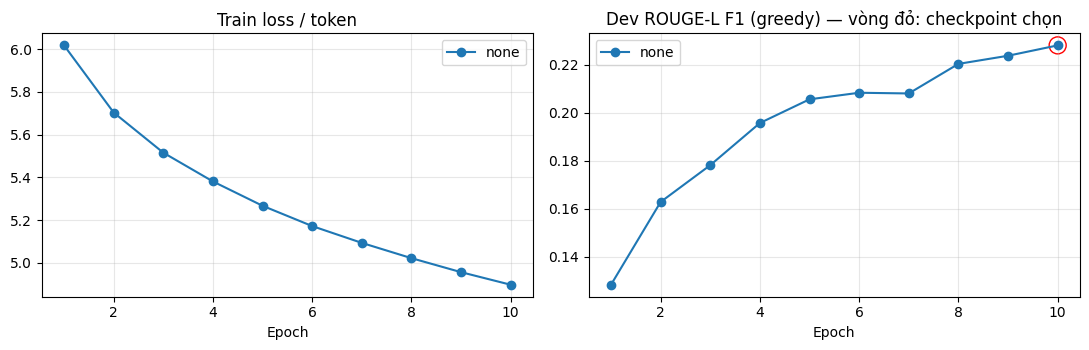

In [19]:
plot_history(['none'], 'bai1_learning_curves.png')

In [20]:
# 3 câu dịch mẫu trên tập test
show_examples('none')

[tốt] id=907  ROUGE-L=0.857
  EN  : ( laughter ) ( applause ) thank you .
  REF : ( cười ) ( vỗ tay ) cám ơn .
  HYP : ( tiếng cười ) ( vỗ tay ) cảm ơn . 

[trung bình] id=853  ROUGE-L=0.240
  EN  : and then i saw this quote : " advertising is the price companies pay for being unoriginal . "
  REF : và sau đó tôi nhìn thấy câu nói này : " quảng cáo là cái giá mà công ty phải trả để trở thành không độc đáo . "
  HYP : và tôi đã nói rằng một " " " " là một một là một một một một một một . 

[kém] id=58  ROUGE-L=0.000
  EN  : lifetime employment for public employees abolished from today
  REF : bãi bỏ viên chức suốt đời cho cán bộ nhà nước từ hôm nay
  HYP : những người có thể có thể <unk> <unk> <unk> <unk> <unk> . 



**Nhận xét Bài 1:**

- ROUGE-L test = **0.2304** (dev 0.2281), BLEU test = 2.46. Checkpoint tốt nhất là epoch 10: loss train và ROUGE-L dev vẫn cải thiện đến epoch cuối (chững lại ở epoch 6-7), nên mô hình chưa hội tụ; kết quả là ở mức 10 epoch, chưa phải năng lực tối đa của mô hình.
- Câu tốt (id 907, 0.857): câu ngắn, cụm "( cười ) ( vỗ tay )" xuất hiện rất nhiều trong dữ liệu nên mô hình dịch gần đúng; khác biệt chỉ là "cảm ơn"/"cám ơn" và thêm từ "tiếng".
- Câu trung bình (id 853, 0.240): mở đầu đúng "và ... tôi", giữ được dấu ngoặc kép nhưng sau đó lặp "một ... là một một". Câu dài 19 token, chỉ 1 từ ngoài từ điển (unoriginal); nguyên nhân có thể là cả câu bị nén vào một cặp (h, c) cố định nên decoder mất thông tin và quay về các từ phổ biến.
- Câu kém (id 58, 0.000): tiêu đề tin tức, chỉ 1/8 từ nguồn ngoài từ điển (abolished) nhưng mô hình vẫn sinh "có thể" và chuỗi `<unk>`, nên lỗi này không chỉ do từ ngoài từ điển.
- Trên toàn tập test (ô thống kê lỗi ở phần so sánh): chỉ 3.8% câu đạt ROUGE-L >= 0.5; 81% câu dịch có ít nhất một từ bị lặp liền nhau (không tính dấu chấm, dấu phẩy); câu dịch ngắn hơn tham chiếu (19.9 so với 24.7 từ) nên recall (0.208) thấp hơn precision (0.262).

## Bài 2. Encoder-Decoder LSTM + Bahdanau attention

Theo Bahdanau và cộng sự (2015): tại mỗi bước, decoder dùng trạng thái ẩn bước trước $h_{t-1}$ làm query, tính điểm cộng $e_{t,s}=v^\top\tanh(W_q h_{t-1}+W_k\bar h_s)$ với mọi trạng thái encoder, softmax ra $\alpha_{t,s}$, lấy context $c_t=\sum_s\alpha_{t,s}\bar h_s$ rồi nối $c_t$ với embedding của từ trước làm đầu vào LSTM. Các điểm khác bài báo gốc (giữ theo notebook mẫu và cấu hình chung của đề): encoder là LSTM một chiều 3 lớp thay vì BiRNN; query là trạng thái của lớp LSTM trên cùng; decoder được khởi tạo bằng chính (h, c) của encoder thay vì qua tanh(W_s h_1); lớp đầu ra dùng tanh(W[h_t; c_t]) giống Luong thay cho maxout.

In [21]:
r2 = run_experiment('bahdanau')

bahdanau  epoch  1 | loss=6.0433 | dev NLL=5.9273 | dev ROUGE-L=0.1249 | BLEU=0.11 | 147s


bahdanau  epoch  2 | loss=5.6433 | dev NLL=5.5088 | dev ROUGE-L=0.1963 | BLEU=1.04 | 140s


bahdanau  epoch  3 | loss=5.3604 | dev NLL=5.2644 | dev ROUGE-L=0.2206 | BLEU=1.78 | 141s


bahdanau  epoch  4 | loss=5.1642 | dev NLL=5.0770 | dev ROUGE-L=0.2319 | BLEU=2.15 | 143s


bahdanau  epoch  5 | loss=5.0008 | dev NLL=4.9141 | dev ROUGE-L=0.2554 | BLEU=2.84 | 141s


bahdanau  epoch  6 | loss=4.8668 | dev NLL=4.8082 | dev ROUGE-L=0.2677 | BLEU=3.24 | 142s


bahdanau  epoch  7 | loss=4.7580 | dev NLL=4.7118 | dev ROUGE-L=0.2719 | BLEU=3.60 | 143s


bahdanau  epoch  8 | loss=4.6575 | dev NLL=4.6430 | dev ROUGE-L=0.2863 | BLEU=4.00 | 142s


bahdanau  epoch  9 | loss=4.5673 | dev NLL=4.5614 | dev ROUGE-L=0.2932 | BLEU=4.35 | 139s


bahdanau  epoch 10 | loss=4.4884 | dev NLL=4.5069 | dev ROUGE-L=0.2998 | BLEU=4.73 | 140s
→ bahdanau: chọn checkpoint epoch 10 (dev ROUGE-L = 0.2998)


model                  bahdanau
parameters              8025763
best_epoch                   10
dev_rougeL              0.29979
dev_bleu               4.734679
test_rougeL            0.313622
test_rougeL_P          0.332922
test_rougeL_R          0.300813
test_bleu              6.021779
seconds_per_epoch    141.809386


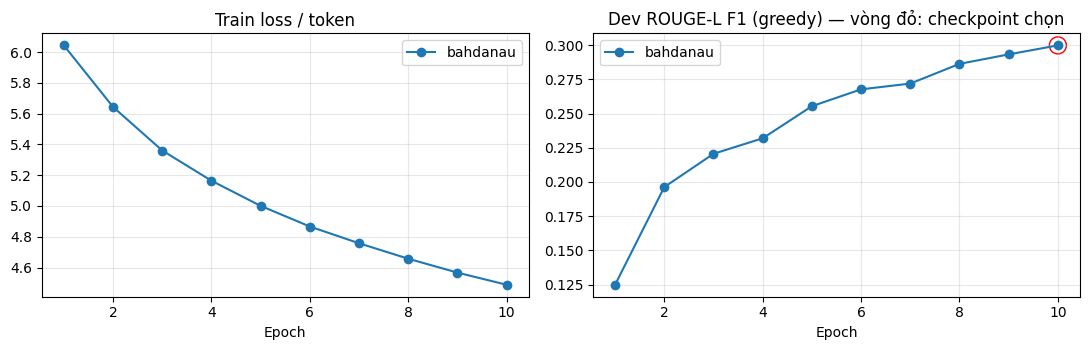

In [22]:
plot_history(['bahdanau'], 'bai2_learning_curves.png')

In [23]:
show_examples('bahdanau')

[tốt] id=851  ROUGE-L=0.889
  EN  : it was n't what i wanted to do .
  REF : đó không phải là điều mà tôi muốn làm .
  HYP : đó không phải là tôi muốn làm . 

[trung bình] id=833  ROUGE-L=0.333
  EN  : it was really a death trap .
  REF : nó thực sự là một cái bẫy chết người .
  HYP : đó là một là một trò chơi . 

[kém] id=75  ROUGE-L=0.000
  EN  : dismantling saigon 's binh trieu tollgates finished
  REF : đã hoàn thành việc tháo dỡ các trạm thu phí bình triệu ở sài gòn
  HYP : <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> 



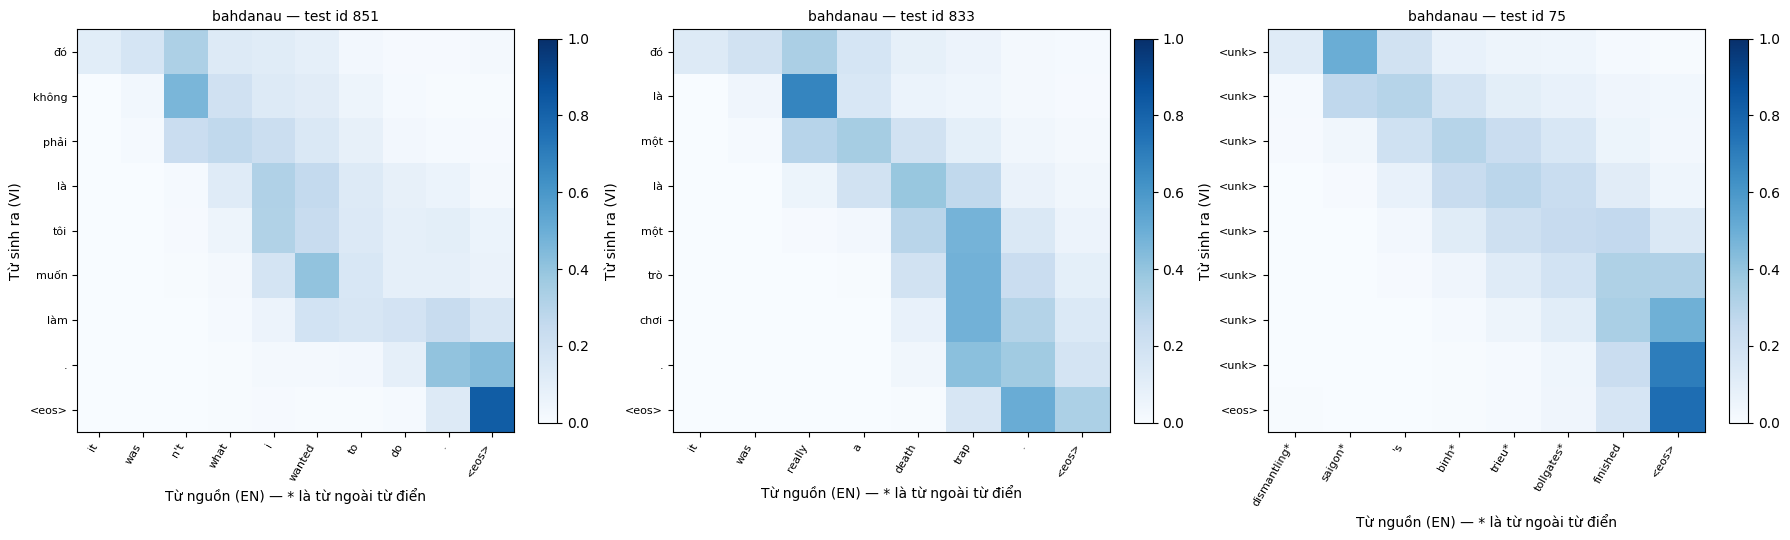

In [24]:
# Heatmap attention trên 3 câu mẫu (tốt / trung bình / kém) của Bahdanau
attn_ids = [o['id'] for _, o in pick_examples(results['bahdanau']['outputs'])]
plot_attention('bahdanau', attn_ids, 'bai2_attention_bahdanau.png')

**Nhận xét Bài 2:**

- ROUGE-L test = **0.3136** (dev 0.2998), BLEU test = 6.02, tăng 0.083 ROUGE-L (khoảng +36%) so với Bài 1. Mô hình học nhanh hơn: sau 2 epoch đã đạt 0.196 trên dev, bằng Bài 1 sau 4 epoch. Đến epoch 10 vẫn còn tăng.
- Câu mẫu: id 851 dịch gần đúng "đó không phải là tôi muốn làm ." (chỉ thiếu "điều mà"); id 833 không có từ ngoài từ điển nhưng dịch sai "death trap" thành "trò chơi" và lặp "là một"; id 75 có 5/7 từ nguồn ngoài từ điển (dismantling, saigon, binh, trieu, tollgates) nên ra toàn `<unk>`.
- Heatmap: trọng số tập trung quanh đường chéo, tức mô hình học được căn chỉnh gần như đơn điệu giữa tiếng Anh và tiếng Việt (cùng trật tự chủ - vị - tân). Ví dụ "không" chú ý vào "n't", "muốn" vào "wanted", "." vào ".", `<eos>` vào `<eos>`.
- Ở câu 833, từ "trò chơi" chú ý đúng vào "trap" nhưng chọn sai nghĩa: attention tìm đúng vị trí nhưng decoder chưa dịch đúng từ. Ở câu 75, attention vẫn đi dần từ trái sang phải nhưng hầu hết từ nguồn là `<unk>` nên gần như không có thông tin để dịch.
- Phân phối attention khá "mềm", thường trải trên 2-3 từ nguồn liền kề.
- Chi phí: 8.03 triệu tham số (+7% so với Bài 1), 142 giây/epoch (+65%) vì mỗi bước giải mã phải tính attention trên toàn bộ câu nguồn.

## Bài 3. Encoder-Decoder LSTM + Luong attention

Theo Luong và cộng sự (2015), dạng **global attention, hàm điểm general**: LSTM cập nhật trước để có $h_t$, dùng $h_t$ làm query với điểm $\text{score}(h_t,\bar h_s)=h_t^\top W\bar h_s$, tính context $c_t$, rồi tạo vector attentional $\tilde h_t=\tanh(W_c[c_t;h_t])$ để dự đoán từ. $\tilde h_t$ được nối vào đầu vào của bước sau (input-feeding).

In [25]:
r3 = run_experiment('luong')

luong     epoch  1 | loss=6.0741 | dev NLL=5.9754 | dev ROUGE-L=0.1291 | BLEU=0.11 | 138s


luong     epoch  2 | loss=5.7438 | dev NLL=5.6469 | dev ROUGE-L=0.1688 | BLEU=0.90 | 138s


luong     epoch  3 | loss=5.4966 | dev NLL=5.3835 | dev ROUGE-L=0.1864 | BLEU=1.27 | 139s


luong     epoch  4 | loss=5.2867 | dev NLL=5.1738 | dev ROUGE-L=0.2141 | BLEU=1.66 | 137s


luong     epoch  5 | loss=5.1117 | dev NLL=4.9977 | dev ROUGE-L=0.2370 | BLEU=2.37 | 138s


luong     epoch  6 | loss=4.9615 | dev NLL=4.8605 | dev ROUGE-L=0.2553 | BLEU=2.80 | 137s


luong     epoch  7 | loss=4.8377 | dev NLL=4.7426 | dev ROUGE-L=0.2618 | BLEU=3.14 | 140s


luong     epoch  8 | loss=4.7276 | dev NLL=4.6569 | dev ROUGE-L=0.2760 | BLEU=3.79 | 139s


luong     epoch  9 | loss=4.6275 | dev NLL=4.5841 | dev ROUGE-L=0.2842 | BLEU=4.15 | 139s


luong     epoch 10 | loss=4.5377 | dev NLL=4.4983 | dev ROUGE-L=0.2915 | BLEU=4.72 | 140s
→ luong: chọn checkpoint epoch 10 (dev ROUGE-L = 0.2915)


model                     luong
parameters              7959971
best_epoch                   10
dev_rougeL             0.291461
dev_bleu               4.715058
test_rougeL            0.300719
test_rougeL_P           0.32159
test_rougeL_R          0.286408
test_bleu              5.495587
seconds_per_epoch    138.424797


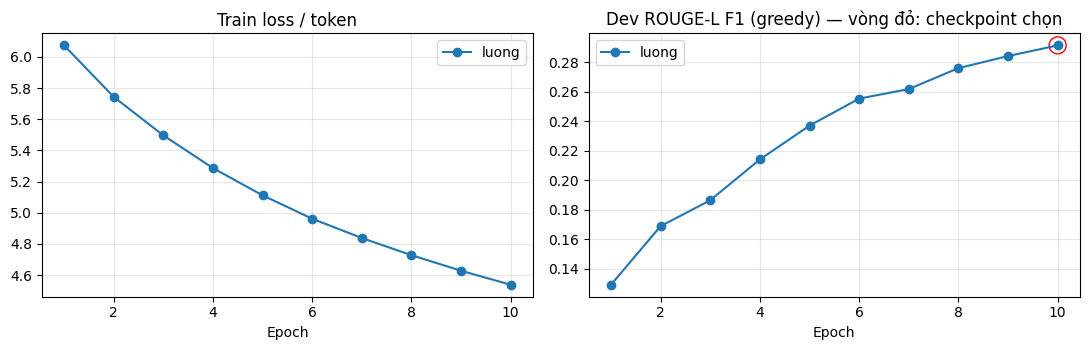

In [26]:
plot_history(['luong'], 'bai3_learning_curves.png')

In [27]:
show_examples('luong')

[tốt] id=907  ROUGE-L=0.857
  EN  : ( laughter ) ( applause ) thank you .
  REF : ( cười ) ( vỗ tay ) cám ơn .
  HYP : ( tiếng cười ) ( vỗ tay ) cảm ơn . 

[trung bình] id=1971  ROUGE-L=0.316
  EN  : in fact , it became the oldest continuously operating company in the world .
  REF : thật ra , nó trở thành công ti điều hành liên tục lâu đời nhất trên thế giới .
  HYP : thực tế , nó đã tạo ra những sự phân động của các công dân trong thế giới . 

[kém] id=65  ROUGE-L=0.000
  EN  : v - pop prince 's documentary soundtrack among global music charts
  REF : nhạc phim tài liệu của hoàng tử v-pop lọt vào các bảng xếp hạng âm nhạc toàn cầu
  HYP : <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> 



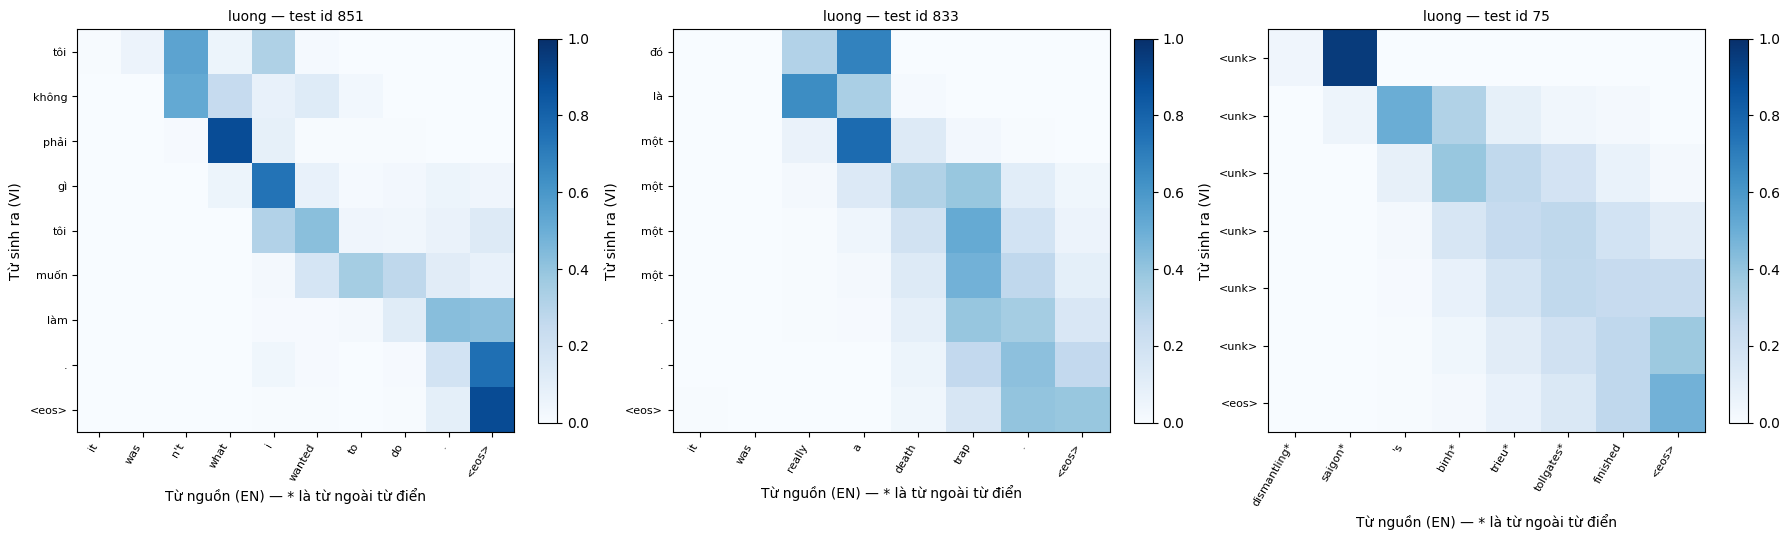

In [28]:
# Heatmap Luong trên đúng 3 câu đã dùng cho Bahdanau để so sánh trực tiếp
plot_attention('luong', attn_ids, 'bai3_attention_luong.png')

### So sánh ba mô hình

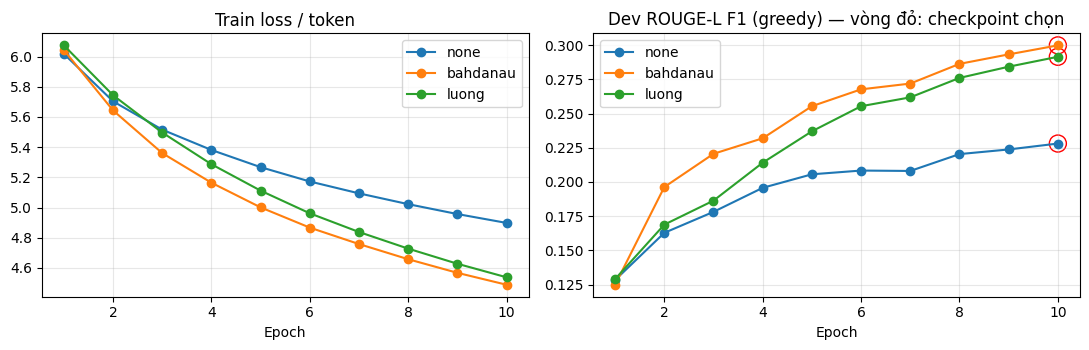

In [29]:
# Đồ thị học của cả 3 mô hình trên cùng một hình
plot_history(['none', 'bahdanau', 'luong'], 'compare_learning_curves.png')

In [30]:
# Cùng 3 câu test, bản dịch của 3 mô hình
outs = {m: {o['id']: o for o in results[m]['outputs']} for m in results}
for sid in attn_ids:
    o = outs['none'][sid]
    print(f'id={sid}\n  EN  : {o["english"]}\n  REF : {o["reference"]}')
    for m in ['none', 'bahdanau', 'luong']:
        print(f'  {m:9}: {outs[m][sid]["hypothesis"]}   (ROUGE-L={outs[m][sid]["rougeL"]:.3f})')
    print()

id=851
  EN  : it was n't what i wanted to do .
  REF : đó không phải là điều mà tôi muốn làm .
  none     : đó không phải tôi không làm gì .   (ROUGE-L=0.667)
  bahdanau : đó không phải là tôi muốn làm .   (ROUGE-L=0.889)
  luong    : tôi không phải gì tôi muốn làm .   (ROUGE-L=0.667)

id=833
  EN  : it was really a death trap .
  REF : nó thực sự là một cái bẫy chết người .
  none     : đó là một một một một . .   (ROUGE-L=0.333)
  bahdanau : đó là một là một trò chơi .   (ROUGE-L=0.333)
  luong    : đó là một một một một . .   (ROUGE-L=0.333)

id=75
  EN  : dismantling saigon 's binh trieu tollgates finished
  REF : đã hoàn thành việc tháo dỡ các trạm thu phí bình triệu ở sài gòn
  none     : <unk> <unk> <unk> <unk> <unk> <unk> <unk> .   (ROUGE-L=0.000)
  bahdanau : <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>   (ROUGE-L=0.000)
  luong    : <unk> <unk> <unk> <unk> <unk> <unk>   (ROUGE-L=0.000)



          none  bahdanau   luong  so_cau
do_dai                                  
1-10    0.3360    0.4035  0.3886     318
11-20   0.2357    0.3225  0.3066     688
21-30   0.1896    0.2761  0.2669     531
31-50   0.1677    0.2544  0.2442     249


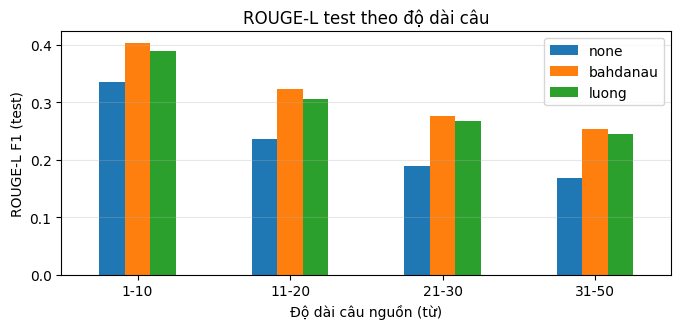

In [31]:
# ROUGE-L test theo độ dài câu nguồn: attention có giúp câu dài không?
bins = [0, 10, 20, 30, 51]
labels = ['1-10', '11-20', '21-30', '31-50']
frames = []
for m in ['none', 'bahdanau', 'luong']:
    d = pd.DataFrame(results[m]['outputs'])
    d['do_dai'] = pd.cut(d.english.str.split().str.len(), bins=bins, labels=labels)
    frames.append(d.groupby('do_dai', observed=False).rougeL.mean().rename(m))
by_len = pd.concat(frames, axis=1)
by_len['so_cau'] = pd.DataFrame(results['none']['outputs']).english.str.split().str.len() \
    .pipe(pd.cut, bins=bins, labels=labels).value_counts().sort_index()
print(by_len.round(4).to_string())
by_len.to_csv(ART/'rougeL_by_length.csv')
ax = by_len[['none', 'bahdanau', 'luong']].plot.bar(figsize=(7, 3.4), rot=0)
ax.set_xlabel('Độ dài câu nguồn (từ)'); ax.set_ylabel('ROUGE-L F1 (test)'); ax.grid(alpha=0.3, axis='y')
ax.set_title('ROUGE-L test theo độ dài câu'); plt.tight_layout()
plt.savefig(ART/'rougeL_by_length.png', dpi=150); plt.show()

In [ ]:
# Ô bổ sung sau lần chạy trên Colab: thống kê lỗi trên tập test, tính lại từ các file CSV trong artifacts/
# "Lặp liền nhau": có ít nhất một token (không tính dấu chấm, dấu phẩy) xuất hiện 2 lần liên tiếp
def error_stats(mode):
    d = pd.read_csv(ART/f'{mode}_test_translations.csv').fillna('')
    hyp, ref = d.hypothesis.str.split(), d.reference.str.split()
    lap = hyp.apply(lambda t: any(a == b and a not in ('.', ',') for a, b in zip(t, t[1:])))
    return {'Câu đạt ROUGE-L >= 0.5 (%)': 100 * (d.rougeL >= 0.5).mean(),
            'Câu dịch có <unk> (%)': 100 * d.hypothesis.str.contains('<unk>', regex=False).mean(),
            'Câu dịch có từ lặp liền nhau (%)': 100 * lap.mean(),
            'Độ dài câu dịch (TB)': hyp.str.len().mean(),
            'Độ dài tham chiếu (TB)': ref.str.len().mean()}

print(pd.DataFrame({m: error_stats(m) for m in ['none', 'bahdanau', 'luong']}).round(1).to_string())
ref_oov = np.mean([any(t not in tgt_vocab for t in r['tgt']) for r in test_rows])
print(f'\nCâu tham chiếu test có từ tiếng Việt ngoài từ điển: {100 * ref_oov:.1f}%\n')

# Số từ nguồn ngoài từ điển của các câu mẫu
by_id = {r['id']: r for r in test_rows}
for sid in [907, 853, 58, 851, 833, 75, 1971, 65]:
    src = by_id[sid]['src']
    oov = [t for t in src if t not in src_vocab]
    print(f'id {sid}: {len(oov)}/{len(src)} từ ngoài từ điển {oov}')

                                  none  bahdanau  luong
Câu đạt ROUGE-L >= 0.5 (%)         3.8      11.4    9.4
Câu dịch có <unk> (%)             18.7      31.0   33.5
Câu dịch có từ lặp liền nhau (%)  81.1      87.7   89.3
Độ dài câu dịch (TB)              19.9      22.7   22.4
Độ dài tham chiếu (TB)            24.7      24.7   24.7

Câu tham chiếu test có từ tiếng Việt ngoài từ điển: 28.8%

id 907: 0/9 từ ngoài từ điển []
id 853: 1/19 từ ngoài từ điển ['unoriginal']
id 58: 1/8 từ ngoài từ điển ['abolished']
id 851: 0/9 từ ngoài từ điển []
id 833: 0/7 từ ngoài từ điển []
id 75: 5/7 từ ngoài từ điển ['dismantling', 'saigon', 'binh', 'trieu', 'tollgates']
id 1971: 1/14 từ ngoài từ điển ['continuously']
id 65: 3/11 từ ngoài từ điển ['v', 'documentary', 'soundtrack']


### Bảng tổng hợp kết quả (C.2)

In [32]:
names = {'none': 'Bài 1. Không attention', 'bahdanau': 'Bài 2. Bahdanau', 'luong': 'Bài 3. Luong'}
table = pd.DataFrame([{
    'Mô hình': names[m],
    'ROUGE-L dev': s['dev_rougeL'], 'ROUGE-L test': s['test_rougeL'],
    'Số tham số': s['parameters'], 'Giây/epoch': s['seconds_per_epoch'],
    'Epoch tốt nhất': s['best_epoch'], 'BLEU test': s['test_bleu'],
} for m in ['none', 'bahdanau', 'luong'] for s in [results[m]['summary']]])
table.to_csv(ART/'summary_table.csv', index=False)
(ART/'config.json').write_text(json.dumps(dict(cfg=cfg, device=str(device), torch=torch.__version__,
    gpu=torch.cuda.get_device_name(0) if device.type == 'cuda' else None,
    vocab=dict(src=len(src_vocab), tgt=len(tgt_vocab)),
    sizes=dict(train=len(train_rows), dev=len(dev_rows), test=len(test_rows))), indent=2), encoding='utf-8')
table.style.format({'ROUGE-L dev': '{:.4f}', 'ROUGE-L test': '{:.4f}', 'Số tham số': '{:,}',
                    'Giây/epoch': '{:.1f}', 'BLEU test': '{:.2f}'}).hide(axis='index')

Mô hình,ROUGE-L dev,ROUGE-L test,Số tham số,Giây/epoch,Epoch tốt nhất,BLEU test
Bài 1. Không attention,0.2281,0.2304,"7,500,963",85.7,10,2.46
Bài 2. Bahdanau,0.2998,0.3136,"8,025,763",141.8,10,6.02
Bài 3. Luong,0.2915,0.3007,"7,959,971",138.4,10,5.50


**Nhận xét Bài 3:**

- ROUGE-L test = **0.3007** (dev 0.2915), BLEU test = 5.50, tăng 0.070 so với Bài 1 nhưng thấp hơn Bahdanau 0.013.
- Câu mẫu: id 907 dịch gần đúng như Bài 1; id 1971 giữ được khung câu "thực tế , nó ... thế giới ." nhưng sai nghĩa phần giữa; id 65 chỉ có 3/11 từ nguồn ngoài từ điển (v, documentary, soundtrack) nhưng mô hình vẫn ra toàn `<unk>`, nên lỗi này không chỉ do từ ngoài từ điển.
- Heatmap Luong cũng theo đường chéo nhưng **nhọn hơn** Bahdanau: nhiều ô đạt 0.8-1.0 (ví dụ "phải" vào "what", `<unk>` đầu tiên vào "saigon"). Có thể vì query là trạng thái hiện tại h_t và điểm general là dạng tích song tuyến nên phân phối dễ dồn vào một từ. Tuy nhiên nhọn hơn không có nghĩa là đúng hơn: ở câu 851, Luong mở đầu bằng "tôi" và chèn "gì" không đúng ngữ cảnh (ROUGE-L 0.667, so với 0.889 của Bahdanau).

**So sánh ba mô hình:**

- Thứ tự **Bahdanau > Luong > không attention** nhất quán trên dev, test, BLEU và ở mọi nhóm độ dài câu.
- Attention giúp decoder nhìn lại toàn bộ câu nguồn ở mỗi bước thay vì chỉ dựa vào một vector ngữ cảnh cố định. Lợi ích này rõ hơn ở câu dài: khoảng cách ROUGE-L giữa Bahdanau và mô hình không attention tăng từ 0.067 (câu 1-10 từ) lên 0.087 (câu 31-50 từ); với Luong là 0.053 lên 0.077.
- Bahdanau nhỉnh hơn Luong một chút. Trong cài đặt này, cả hai đều ghép context với trạng thái ẩn qua tanh(W[h_t; c_t]) trước lớp đầu ra. Khác biệt là Bahdanau tính context từ h_(t-1) và còn đưa context vào đầu vào LSTM ngay ở bước hiện tại (dùng context hai lần), còn Luong tính context từ h_t và chỉ đưa nó vào LSTM ở bước sau qua input-feeding; hàm điểm cộng có tanh cũng có thêm tham số. Đây chỉ là giải thích khả dĩ: chênh lệch nhỏ (0.013 trên test, 0.008 trên dev) và chỉ từ một lần chạy với một seed nên chưa đủ để khẳng định.
- Hạn chế chung: cả 3 mô hình đều chọn epoch 10 và vẫn đang tăng, tức chưa hội tụ. Lỗi lặp từ rất phổ biến (81-89% câu dịch), một phần có thể do giải mã greedy và mô hình chưa hội tụ. Nhiều câu dịch chứa `<unk>` (19% ở Bài 1, 31-34% ở hai mô hình attention); bản thân 29% câu tham chiếu test cũng có từ tiếng Việt ngoài từ điển. Mô hình attention sinh `<unk>` nhiều hơn, có thể vì nó căn chỉnh trực tiếp vào các từ nguồn hiếm (giả thuyết, chưa kiểm chứng).